Dataset Used: https://www.kaggle.com/datasets/tongpython/cat-and-dog

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras.layers import Input,Dense,Conv2D,Conv2DTranspose, MaxPooling2D, UpSampling2D
from keras.models import Model
from keras.preprocessing import image

In [ ]:
cat_train_path = "../cat_and_dog/training_set/training_set/cats/"
cat_test_path = "../cat_and_dog/test_set/test_set/cats/"

cat_train = []
for filename in os.listdir(cat_train_path):
    if filename.endswith(".jpg"):
        img = image.load_img(cat_train_path+filename, target_size=(128, 128))
        cat_train.append(image.img_to_array(img))
cat_train = np.array(cat_train)

cat_test = []
for filename in os.listdir(cat_test_path):
    if filename.endswith(".jpg"):
        img = image.load_img(cat_test_path+filename, target_size=(128, 128))
        cat_test.append(image.img_to_array(img))
cat_test = np.array(cat_test)

In [3]:
print("cat_train", cat_train.shape)
print("cat_test", cat_test.shape)

cat_train (4000, 128, 128, 3)
cat_test (1011, 128, 128, 3)


In [14]:
def show_data(X, n=10, height=28, width=28, title=''):
    plt.figure(figsize=(10,3))
    for i in range(n):
        ax = plt.subplot(2,n,i+1)
        plt.imshow(X[i].reshape((height,width)))
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
    plt.suptitle(title, fontsize = 20)

In [4]:
def show_cat_data(X, n=10, title=""):
    plt.figure(figsize=(15, 5))
    for i in range(n):
        ax = plt.subplot(2,n,i+1)
        plt.imshow(image.array_to_img(X[i]))
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
    plt.suptitle(title, fontsize = 20)

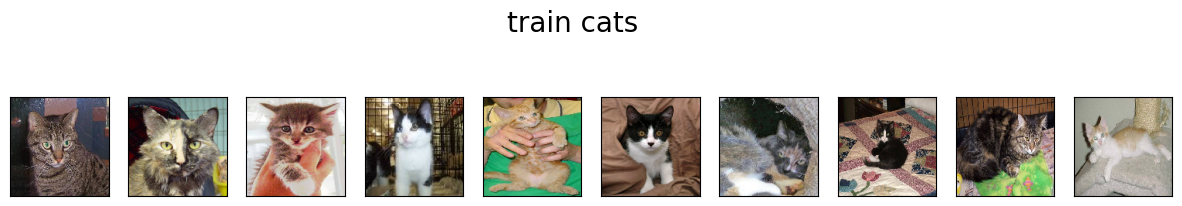

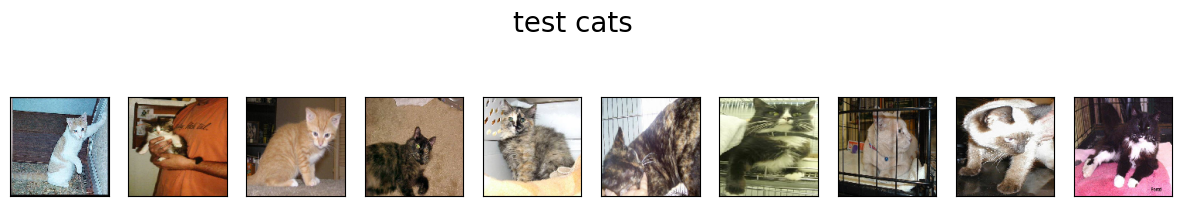

In [5]:
show_cat_data(cat_train, title="train cats")
show_cat_data(cat_test, title="test cats")

<h2>Build the Convolutional Autoencoder</h2>

In [6]:
input_layer = Input(shape=(128,128,3), name='INPUT')
x = Conv2D(16,(3,3), activation='relu', padding='same')(input_layer)
x = MaxPooling2D((2,2))(x)
x = Conv2D(8,(3,3), activation='relu', padding='same')(x)
x = MaxPooling2D((2,2))(x)
x = Conv2D(8,(3,3), activation='relu', padding='same')(x)

code_layer = MaxPooling2D((2,2), name='CODE')(x)

x = Conv2DTranspose(8,(3,3), activation='relu', padding='same')(code_layer)
x = UpSampling2D((2,2))(x)
x = Conv2DTranspose(8,(3,3), activation='relu', padding='same')(x)
x = UpSampling2D((2,2))(x)
x = Conv2DTranspose(16,(3,3), activation='relu', padding='same')(x)
x = UpSampling2D((2,2))(x)
output_layer = Conv2D(3,(3,3), padding = 'same', name = 'OUTPUT')(x)

In [7]:
cat_AE = Model(input_layer,output_layer)
cat_AE.compile(optimizer='adam', loss='mse')
cat_AE.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ INPUT (InputLayer)                   │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 8)           │           1,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 8)           │             584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ CODE (MaxPooling2D)                  │ (None, 16, 16, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)   │ (None, 16, 16, 8)           │             584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d (UpSampling2D)         │ (None, 32, 32, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose) │ (None, 32, 32, 8)           │             584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_1 (UpSampling2D)       │ (None, 64, 64, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_2 (Conv2DTranspose) │ (None, 64, 64, 16)          │           1,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_2 (UpSampling2D)       │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ OUTPUT (Conv2D)                      │ (None, 128, 128, 3)         │             435 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,963 (19.39 KB)

 Trainable params: 4,963 (19.39 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
cat_AE.fit(cat_train,cat_train,
          epochs=30,
          batch_size=32,
          shuffle=True,
          validation_data=(cat_test,cat_test))

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - loss: 2410.4963 - val_loss: 1057.7487
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - loss: 895.0327 - val_loss: 813.7522
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - loss: 738.4083 - val_loss: 711.0712
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - loss: 659.6830 - val_loss: 645.6517
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - loss: 620.4907 - val_loss: 615.8257
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - loss: 595.1047 - val_loss: 592.9648
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - loss: 576.2753 - val_loss: 577.6329
Epoch 8/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - loss: 563.8158 - val_loss: 566.7247
Epoch 9/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - loss: 553.3103 - val_loss: 555.0029
Epoch 10/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - loss: 544.2659 - val_loss: 548.2301
Epoch 11/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - loss: 536.0740 - val_loss: 539

<h2>Save Model</h2>

In [9]:
cat_AE.save('cat_AE.h5')

In [10]:
get_encoded_cat = Model(inputs=cat_AE.input, outputs=cat_AE.get_layer('CODE').output)

<h2>Get the encoded cats</h2>

In [11]:
encoded_cat = get_encoded_cat.predict(cat_test)
encoded_cat = encoded_cat.reshape(len(cat_test), 16*16*8)
encoded_cat.shape

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


(1011, 2048)

<h2>Get the reconstructed cats</h2>

In [12]:
reconstructed_cats = cat_AE.predict(cat_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step


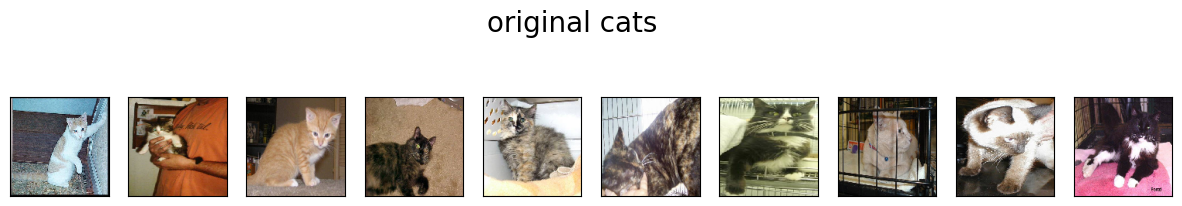

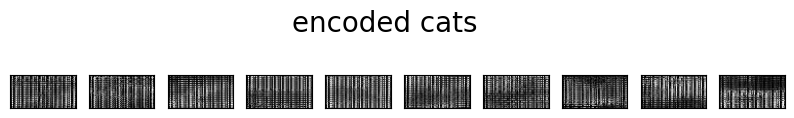

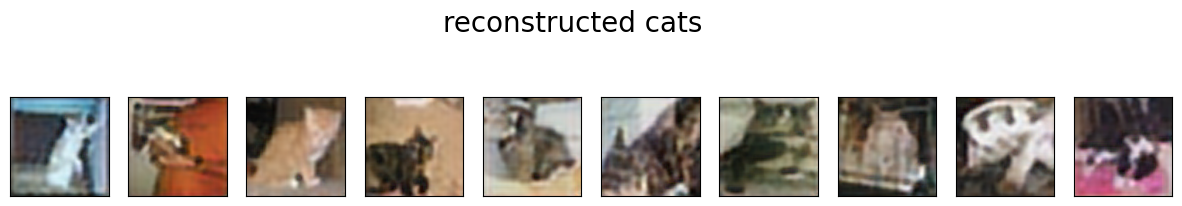

In [15]:
show_cat_data(cat_test, title='original cats')
show_data(encoded_cat, height=32, width=64, title='encoded cats')
show_cat_data(reconstructed_cats, title='reconstructed cats')